# 00 · Qualité des données et ground truth : les données sont-elles exploitables ?

Ce notebook précède les trois autres de la série (`01` comprendre les données, `02` benchmark et
fuite, `03` KPIs et dashboard). Il ne contient aucune logique métier : tous les contrôles sont
implémentés dans `alm_monitoring.data_audit` et la préparation dans `alm_monitoring.data.lending_club`,
le notebook les appelle et commente les résultats.

**Plan**

1. Pourquoi auditer avant de modéliser et avant de monitorer
2. L'audit complet : exécution sur l'échantillon, résultats sur le fichier complet
3. Lecture constat par constat (dix familles de contrôle)
4. Effet du nettoyage (`clean=False` vs `clean=True`)
5. Aperçu du feature engineering
6. Verdict et ce que l'audit rejoue en production

## 1. Pourquoi auditer avant de modéliser et avant de monitorer

Un modèle entraîné sur des données dupliquées, des revenus à 61 millions de dollars ou une cible
incohérente apprend du bruit, et aucun KPI de monitoring ne le révélera ensuite : la dérive se mesure
par rapport à une référence, et une référence corrompue rend la mesure aveugle. L'audit répond donc à
une question préalable, « peut-on entraîner et surveiller un modèle sur ces données ? », par un verdict
argumenté constat par constat (`ok` / `warning` / `critical`), et non par un nettoyage silencieux.
Chaque décision prise ici (valeurs neutralisées, manquants conservés, pas de rééquilibrage) est tracée
pour être rejouée à l'identique en production.

In [1]:
import json
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

pio.renderers.default = "notebook+png"  # +png : figure statique visible sur GitHub
pd.set_option("display.max_rows", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

from alm_monitoring import data_audit as da
from alm_monitoring.data import lending_club as lc

ROOT = ".."
SAMPLE_PATH = f"{ROOT}/data/sample/lending_club_sample.csv.gz"
AUDIT_JSON = f"{ROOT}/reports/data_audit_lending_club.json"
DUPLICATE_KEYS = [
    "loan_amnt",
    "int_rate",
    "term",
    "issue_d",
    "annual_inc",
    "dti",
    "fico_range_low",
]
print("Cible :", lc.TARGET, "| date :", lc.TIMESTAMP)

Cible : prepaid_12m | date : issue_d


## 2. L'audit complet

### 2.1 Exécution sur l'échantillon

On rejoue la chaîne sur l'**échantillon brut de 62 277 prêts** (quelques secondes). L'audit porte sur
le jeu préparé **avant nettoyage** (`clean=False`) : c'est tout l'intérêt, on veut voir les valeurs
impossibles, pas les masquer. Le brut est passé en parallèle (`raw=`) pour les règles métier qui ont
besoin des colonnes post-octroi (`last_pymnt_d`, `loan_status`).

In [2]:
raw = lc.load_lending_club(SAMPLE_PATH)
prepared = lc.prepare_lending_club(raw, clean=False)
print(f"{len(raw):,} prêts bruts -> {len(prepared):,} prêts préparés (horizon 12 mois écoulé)")

report = da.audit(
    prepared,
    target=lc.TARGET,
    timestamp=lc.TIMESTAMP,
    numeric_features=lc.NUMERIC_FEATURES,
    categorical_features=lc.CATEGORICAL_FEATURES,
    raw=raw,
    rules=da.lending_club_rules(),
    duplicate_keys=DUPLICATE_KEYS,
    source_path=SAMPLE_PATH,
)
print()
print(report.summary())

62,277 prêts bruts -> 57,559 prêts préparés (horizon 12 mois écoulé)



Audit de qualité : NON EXPLOITABLE EN L'ÉTAT (CRITICAL)
- [ok] fingerprint: lending_club_sample.csv.gz : sha256 1e24a6aa63dc50de…
- [ok] duplicates: 0 ligne(s) identique(s), 0 identifiant(s) répété(s), 1 doublon(s) sémantique(s) sur ['loan_amnt', 'int_rate', 'term', 'issue_d', 'annual_inc', 'dti', 'fico_range_low']
- [critical] business_rules: 1180 violation(s) sur 9 règles ; pire règle : 1.52% des lignes
- [critical] missing_values: 1 colonne(s) au-delà de 20 % de manquants ; 3 manquant(s) informatif(s) lié(s) à la cible : ['mort_acc', 'pub_rec_bankruptcies', 'revol_util']
- [warning] outliers: 1 colonne(s) avec plus de 2 % d'observations au-delà de 5 MAD : ['revol_bal']
- [ok] distributions: 6 colonne(s) fortement asymétrique(s) (|skew| > 2) : ['annual_inc', 'revol_bal', 'pub_rec', 'inq_last_6mths', 'pub_rec_bankruptcies', 'dti'] ; sans impact sur les arbres, à transformer pour la logistique
- [ok] cardinality: 0 colonne(s) quasi constante(s) : aucune ; 0 catégorielle(s) à forte car

In [3]:
findings_sample = report.to_dataframe()[["check", "severity", "message"]]
findings_sample.style.set_properties(
    subset=["message"], **{"text-align": "left", "white-space": "normal"}
)

,check,severity,message
0,fingerprint,ok,lending_club_sample.csv.gz : sha256 1e24a6aa63dc50de…
1,duplicates,ok,"0 ligne(s) identique(s), 0 identifiant(s) répété(s), 1 doublon(s) sémantique(s) sur ['loan_amnt', 'int_rate', 'term', 'issue_d', 'annual_inc', 'dti', 'fico_range_low']"
2,business_rules,critical,1180 violation(s) sur 9 règles ; pire règle : 1.52% des lignes
3,missing_values,critical,"1 colonne(s) au-delà de 20 % de manquants ; 3 manquant(s) informatif(s) lié(s) à la cible : ['mort_acc', 'pub_rec_bankruptcies', 'revol_util']"
4,outliers,warning,1 colonne(s) avec plus de 2 % d'observations au-delà de 5 MAD : ['revol_bal']
5,distributions,ok,"6 colonne(s) fortement asymétrique(s) (|skew| > 2) : ['annual_inc', 'revol_bal', 'pub_rec', 'inq_last_6mths', 'pub_rec_bankruptcies', 'dti'] ; sans impact sur les arbres, à transformer pour la logistique"
6,cardinality,ok,0 colonne(s) quasi constante(s) : aucune ; 0 catégorielle(s) à forte cardinalité : aucune
7,multicollinearity,warning,"VIF >= 10 : ['loan_amnt', 'installment'] ; VIF entre 5 et 10 : ['term_months'] (sans impact sur les arbres, à traiter pour la logistique)"
8,temporal_consistency,warning,"130 mois de 2007-06 à 2018-03 ; 0 mois vide(s), 130 mois sous 1000 lignes, 0 date(s) illisible(s)"
9,target_quality,ok,"taux positif 12.7% (déséquilibre modéré), de 8.0% à 17.0% selon l'année"


### 2.2 Résultats sur le fichier complet

L'audit a déjà été exécuté sur les **2 260 668 prêts** du fichier Kaggle (`make audit`, résultats
dans `reports/data_audit_lending_club.json` et `.md`). On les charge sans rien recalculer.

In [4]:
with open(AUDIT_JSON, encoding="utf-8") as handle:
    findings_full = pd.DataFrame(json.load(handle))
print(
    "Verdict complet :",
    "EXPLOITABLE" if (findings_full["severity"] != "critical").all() else "NON EXPLOITABLE",
)
findings_full[["check", "severity", "message"]].style.set_properties(
    subset=["message"], **{"text-align": "left", "white-space": "normal"}
)

Verdict complet : EXPLOITABLE


,check,severity,message
0,fingerprint,ok,accepted_2007_to_2018Q4.csv.gz : sha256 55c16f75120f8976…
1,duplicates,ok,"0 ligne(s) identique(s), 0 identifiant(s) répété(s), 44 doublon(s) sémantique(s) sur ['loan_amnt', 'int_rate', 'term', 'issue_d', 'annual_inc', 'dti', 'fico_range_low']"
2,business_rules,warning,13772 violation(s) sur 9 règles ; pire règle : 0.32% des lignes
3,missing_values,warning,0 colonne(s) au-delà de 20 % de manquants ; 1 manquant(s) informatif(s) lié(s) à la cible : ['mort_acc']
4,outliers,warning,1 colonne(s) avec plus de 2 % d'observations au-delà de 5 MAD : ['revol_bal']
5,distributions,ok,"6 colonne(s) fortement asymétrique(s) (|skew| > 2) : ['annual_inc', 'dti', 'revol_bal', 'pub_rec', 'pub_rec_bankruptcies', 'inq_last_6mths'] ; sans impact sur les arbres, à transformer pour la logistique"
6,cardinality,ok,0 colonne(s) quasi constante(s) : aucune ; 0 catégorielle(s) à forte cardinalité : aucune
7,multicollinearity,warning,"VIF >= 10 : ['loan_amnt', 'installment'] ; VIF entre 5 et 10 : ['term_months'] (sans impact sur les arbres, à traiter pour la logistique)"
8,temporal_consistency,warning,"130 mois de 2007-06 à 2018-03 ; 0 mois vide(s), 36 mois sous 1000 lignes, 0 date(s) illisible(s)"
9,target_quality,ok,"taux positif 14.8% (déséquilibre modéré), de 8.0% à 17.2% selon l'année"


In [5]:
comparaison = findings_sample.merge(
    findings_full[["check", "severity"]], on="check", suffixes=("_echantillon", "_complet")
)
comparaison[["check", "severity_echantillon", "severity_complet"]]

,check,severity_echantillon,severity_complet
0,fingerprint,ok,ok
1,duplicates,ok,ok
2,business_rules,critical,warning
3,missing_values,critical,warning
4,outliers,warning,warning
5,distributions,ok,ok
6,cardinality,ok,ok
7,multicollinearity,warning,warning
8,temporal_consistency,warning,warning
9,target_quality,ok,ok


**Échantillon vs complet : pourquoi les verdicts diffèrent.** Sur le complet, le verdict est
**EXPLOITABLE (WARNING)** ; sur l'échantillon il est **CRITICAL**. Ce n'est pas une contradiction mais
un artefact de l'échantillonnage : l'échantillon est **stratifié par année** (6 000 prêts par an), il
sur-représente donc les cohortes 2007-2012 (10 % du fichier complet, 45 % de l'échantillon). Or ce
sont elles qui concentrent les défauts : `mort_acc` n'est pas renseigné avant 2012 (37 % de manquants
sur l'échantillon contre 2,7 % sur le complet, d'où le seuil critique des 20 % franchi), et les
mensualités incohérentes avec la formule d'annuité sont un défaut des anciens prêts (1,5 % contre
0,09 %). Le seuil « mois sous 1 000 lignes » est par construction toujours franchi sur un échantillon.
**Les décisions sont prises sur les résultats complets** ; l'échantillon sert à illustrer la mécanique
et à lire les tables détaillées.

## 3. Lecture constat par constat

### 3.1 Doublons

Trois niveaux : lignes strictement identiques, identifiant `id` répété, et doublons **sémantiques**
(même montant, taux, durée, mois d'émission, revenu, DTI et FICO : un même dossier saisi deux fois).

In [6]:
dup = report.findings[1]
pd.Series(dup.details).to_frame("echantillon")

,echantillon
exact,0
repeated_ids,0
semantic,1
keys,"[loan_amnt, int_rate, term, issue_d, annual_in..."
rows,62277


**Lecture.** Aucun doublon exact ni identifiant répété, ni sur l'échantillon ni sur le complet. Le
complet compte **44 doublons sémantiques sur 2,26 millions** (0,002 %). Avec 1 572 montants, 639 taux,
130 mois et un FICO par pas de 5, deux emprunteurs distincts peuvent très bien coïncider sur ces sept
clés : ce sont des **collisions plausibles**, pas des saisies doubles (les `id` diffèrent). Sous le seuil
d'alerte de 0,1 %, on **ne dédoublonne pas** : supprimer 44 lignes n'apporterait rien et risquerait de
retirer de vrais prêts.

### 3.2 Règles métier : valeurs impossibles

Neuf règles d'impossibilité (pas de vraisemblance : un revenu de 2 M$ est rare mais possible, un revenu
nul pour un prêt accordé ne l'est pas). La gravité suit la part de lignes touchées par la pire règle
(warning à 0,1 %, critical à 1 %).

In [7]:
report.tables["business_rules"]

,regle,violations,part
0,mensualite_incoherente_avec_annuite (>10 %),949,0.0152
1,utilisation_revolving_superieure_100,167,0.0027
2,"dti_hors_bornes [0, 100]",34,0.0005
3,revenu_annuel_nul_ou_negatif,30,0.0005
4,revenu_annuel_superieur_5M,0,0.0000
5,"taux_hors_bornes (0, 40]",0,0.0000
6,"fico_hors_bornes [300, 850]",0,0.0000
7,montant_nul_ou_negatif,0,0.0000
8,dernier_paiement_avant_emission,0,0.0000


**Lecture.** Sur le complet, la pire règle touche 0,32 % des lignes (`revol_util > 100 %`, 7 343 prêts),
suivie de `dti > 100` (2 563) et du revenu nul (1 667) ; au total **0,6 % des lignes** portent au moins
une valeur impossible. Sur l'échantillon, la règle d'annuité ressort à 1,5 % à cause des anciennes
cohortes (voir § 2.2) ; elle sert de contrôle de cohérence et n'est pas une feature à nettoyer.

**Politique : NaN, pas suppression ni plafonnement** (docstring de `clean_impossible_values`).
Supprimer les lignes introduirait un **biais de sélection** : les revenus nuls sont peut-être des profils
particuliers (retraités, joint apps mal saisies) que le modèle doit continuer à voir. Plafonner
(`revol_util` à 100) **inventerait une valeur**. Passer à NaN est honnête : le modèle d'arbres retenu
gère nativement les manquants, et la logistique les impute explicitement dans son pipeline.

### 3.3 Manquants et leur mécanisme

Le taux de manquants ne suffit pas : il faut savoir si **le fait d'être manquant** est lié à la cible.
La colonne `ratio_cible_manquant_vs_present` compare le taux de prepayment des lignes où la valeur
manque à celui des lignes renseignées. Un ratio loin de 1 signale un manquant informatif (MNAR) qu'il
faut **conserver comme signal**, pas imputer en silence.

In [8]:
report.tables["missing_values"].head(8)

,colonne,taux_manquant,ratio_cible_manquant_vs_present
0,mort_acc,0.3670,0.7266
1,emp_length_years,0.0428,0.8545
2,pub_rec_bankruptcies,0.0237,0.6521
3,revol_util,0.0016,0.7616
4,total_acc,0.0005,1.0860
5,pub_rec,0.0005,1.0860
6,inq_last_6mths,0.0005,1.0860
7,open_acc,0.0005,1.0860


In [9]:
mort_acc_missing = prepared["mort_acc"].isna()
taux = prepared.groupby(mort_acc_missing)[lc.TARGET].agg(prets="size", taux_prepayment="mean")
taux.index = ["mort_acc renseigné", "mort_acc manquant"]
print("Échantillon :")
print(taux)
print()
print(
    "Fichier complet (audit) : 10,3 % de prepayment quand mort_acc manque vs 14,9 % quand il est renseigné"
)

Échantillon :
                    prets  taux_prepayment
mort_acc renseigné  36435           0.1412
mort_acc manquant   21124           0.1026

Fichier complet (audit) : 10,3 % de prepayment quand mort_acc manque vs 14,9 % quand il est renseigné


**Lecture.** Aucune colonne ne dépasse 20 % de manquants sur le complet (max : 6,1 % pour
`emp_length_years`). En revanche `mort_acc` (nombre de comptes hypothécaires) est **manquant de façon
informative** : ratio 0,69 sur le complet, soit un taux de prepayment de **10,3 % contre 14,9 %**.
L'explication est temporelle : la variable n'est collectée qu'à partir de 2012, et les cohortes anciennes
remboursent moins par anticipation. Imputer par la médiane effacerait ce signal ; on crée donc la
feature **`mort_acc_missing`** (voir § 5), tout en gardant `mort_acc` à NaN. Même logique, plus faible,
pour `pub_rec_bankruptcies` (0,07 % de manquants : négligeable).

### 3.4 Valeurs aberrantes robustes

Le score z classique est lui-même déformé par les extrêmes ; on utilise un **z robuste**
(médiane / MAD) et la règle IQR x 3. La table donne la part d'observations au-delà de 5 MAD.

In [10]:
report.tables["outliers"].head(8)

,colonne,part_aberrante_mad5,part_aberrante_iqr3,mediane,max
0,revol_bal,0.0287,0.0252,"10,572.0000","1,207,359.0000"
1,annual_inc,0.0165,0.0153,"61,000.0000","4,000,000.0000"
2,mort_acc,0.0082,0.0008,1.0000,27.0000
3,open_acc,0.0029,0.0035,10.0000,67.0000
4,dti,0.0011,0.0013,15.8600,401.3300
5,total_acc,0.0005,0.0008,22.0000,165.0000
6,installment,0.0002,0.0001,339.6900,"1,566.8000"
7,fico,0.0001,0.0000,697.0000,847.5000


**Lecture.** Une seule colonne au-dessus de 2 % d'observations extrêmes : `revol_bal` (solde
revolving, 2,7 %, maximum 1,7 M$). `annual_inc` suit (1,75 %) avec un **maximum de 61 M$** sur le
complet ; les 93 revenus au-delà de 5 M$ sont déjà traités comme impossibles (§ 3.2). Le reste est
une **vraie queue lourde**, pas une erreur : on ne l'écrête pas. Les arbres y sont insensibles ; pour
la logistique, la transformation log du § 3.5 suffit. Côté monitoring, le PSI est calculé sur des
**classes de quantiles de la référence**, donc lui aussi robuste à ces queues.

### 3.5 Forme des distributions

Asymétrie et aplatissement, avec recommandation de transformation pour un modèle linéaire.

In [11]:
report.tables["distributions"].head(8)

,colonne,asymetrie,aplatissement,transformation_conseillee
0,annual_inc,14.2720,590.7714,log1p ou classes de quantiles (modèle linéaire)
1,revol_bal,10.7357,298.6302,log1p ou classes de quantiles (modèle linéaire)
2,pub_rec,9.7941,301.0719,log1p ou classes de quantiles (modèle linéaire)
3,inq_last_6mths,3.9305,41.0804,log1p ou classes de quantiles (modèle linéaire)
4,pub_rec_bankruptcies,3.8332,19.8201,log1p ou classes de quantiles (modèle linéaire)
5,dti,3.7458,100.0867,log1p ou classes de quantiles (modèle linéaire)
6,mort_acc,1.6359,4.0977,aucune
7,open_acc,1.2362,3.1793,aucune


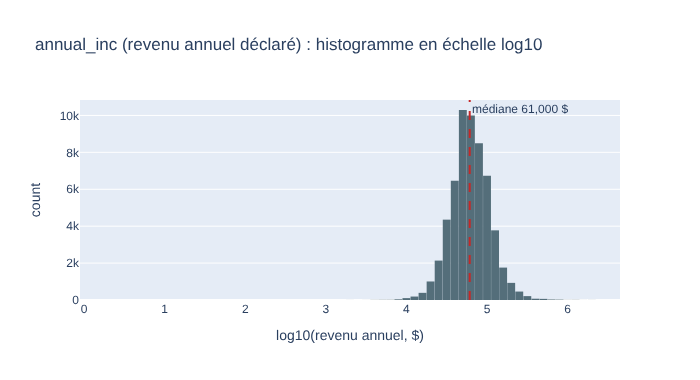

In [12]:
inc = prepared["annual_inc"].dropna()
inc = inc[inc > 0]
fig = px.histogram(
    np.log10(inc),
    nbins=80,
    title="annual_inc (revenu annuel déclaré) : histogramme en échelle log10",
    labels={"value": "log10(revenu annuel, $)"},
    color_discrete_sequence=["#546e7a"],
)
fig.add_vline(
    x=np.log10(inc.median()),
    line_dash="dash",
    line_color="#c62828",
    annotation_text=f"médiane {inc.median():,.0f} $",
    annotation_position="top right",
)
fig.update_layout(showlegend=False, height=380, bargap=0.02)
fig.show()

**Lecture.** Six colonnes fortement asymétriques (|skew| > 2) : `annual_inc` (asymétrie 305 sur le
complet, portée par quelques revenus extrêmes), `dti`, `revol_bal`, `pub_rec`, `pub_rec_bankruptcies`,
`inq_last_6mths`. En log, le revenu redevient à peu près symétrique autour de 65 000 $. **Impact nul
sur les modèles d'arbres** (invariants aux transformations monotones) ; pour la **régression logistique**
du benchmark, `log1p` sur les montants et les comptages est appliqué dans le pipeline, pas dans les
données. Le constat reste donc `ok`.

### 3.6 Cardinalité

Colonnes constantes ou quasi constantes (sans information) et catégorielles à très forte cardinalité
(sur-apprentissage, encodage instable).

In [13]:
report.tables["cardinality"].query("type == 'categorical' or part_modalite_dominante > 0.5")

,colonne,modalites,part_modalite_dominante,type
1,term_months,2,0.7600,numeric
13,pub_rec,16,0.8870,numeric
14,pub_rec_bankruptcies,7,0.8925,numeric
15,inq_last_6mths,29,0.5238,numeric
16,grade,7,0.2985,categorical
17,home_ownership,6,0.4686,categorical
18,purpose,14,0.5319,categorical
19,verification_status,3,0.3884,categorical
20,application_type,2,0.9844,categorical


**Lecture.** Rien à signaler : aucune colonne quasi constante (la plus concentrée est
`pub_rec_bankruptcies`, 88 % de zéros, loin du seuil de 99 %) et les cinq catégorielles ont entre 2 et
14 modalités. Les colonnes à forte cardinalité du fichier Kaggle (`emp_title`, `zip_code`, `addr_state`)
ont été exclues en amont par `load_lending_club`.

### 3.7 Multicolinéarité

Facteurs d'inflation de la variance (VIF = 1 / (1 - R²) de la régression de chaque colonne sur les
autres), calculés sur 50 000 lignes.

In [14]:
report.tables["multicollinearity"].head(6)

,colonne,vif
0,loan_amnt,56.1496
1,installment,47.6410
2,term_months,7.0337
3,int_rate,2.6841
4,total_acc,2.4894
5,open_acc,2.3087


**Lecture.** `loan_amnt` et `installment` ont un VIF d'environ **50** (seuil critique : 10), et
`term_months` est à 7. Ce n'est pas une surprise : la mensualité **est une fonction d'annuité** du
montant, du taux et de la durée (`installment = loan_amnt x r / (1 - (1 + r)^-n)`), c'est d'ailleurs
une des règles métier du § 3.2. Les trois colonnes portent presque la même information. **Conséquence
pour la logistique** : coefficients instables et non interprétables sur ces trois variables (le signe de
`loan_amnt` peut basculer d'un entraînement à l'autre) ; on remplace la mensualité par le taux d'effort
`installment_to_income` (§ 5), qui apporte une information nouvelle. **Aucun impact sur les arbres**,
qui choisissent simplement l'une des colonnes redondantes.

### 3.8 Cohérence temporelle

Volumes par mois d'émission : mois vides (trou dans la collecte), mois trop petits pour être surveillés
(moins de 1 000 lignes, un PSI mensuel y serait du bruit), dates illisibles.

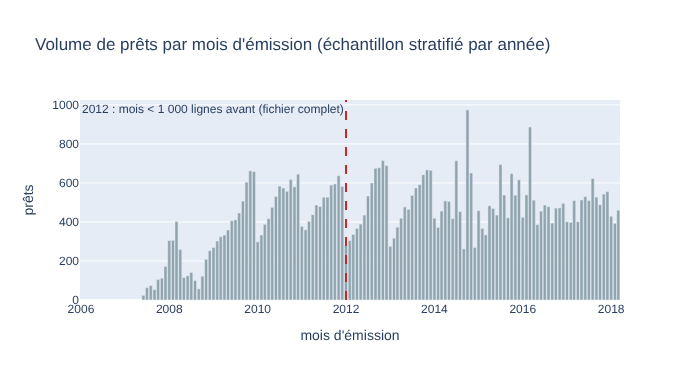

In [15]:
mensuel = report.tables["temporal_consistency"].copy()
mensuel["date"] = pd.PeriodIndex(mensuel["mois"], freq="M").to_timestamp()
fig = px.bar(
    mensuel,
    x="date",
    y="lignes",
    title="Volume de prêts par mois d'émission (échantillon stratifié par année)",
    labels={"date": "mois d'émission", "lignes": "prêts"},
    color_discrete_sequence=["#90a4ae"],
)
fig.add_vline(
    x="2012-01-01",
    line_dash="dash",
    line_color="#c62828",
    annotation_text="2012 : mois < 1 000 lignes avant (fichier complet)",
    annotation_position="top left",
)
fig.update_layout(height=380, bargap=0.1)
fig.show()

**Lecture.** 130 mois consécutifs de juin 2007 à mars 2018, **aucun mois vide, aucune date illisible**.
Sur le fichier complet, les **36 mois antérieurs à 2012** comptent moins de 1 000 prêts (Lending Club
est alors une petite plateforme) : un KPI de dérive mensuel n'y aurait aucun sens, ce qui justifie de
fixer la fenêtre de **référence sur 2013-2015** et la surveillance sur 2016-2017 (notebooks 01 et 03).
Le graphique ci-dessus reflète l'échantillon (6 000 prêts par an, donc 500 par mois) : il montre la
continuité, pas les volumes réels, qui sont présentés par cohorte dans le notebook 01.

### 3.9 Qualité de la cible (ground truth)

Équilibre des classes par année d'émission, statuts ambigus dans `loan_status` et incohérences entre
statut et montants (prêt « soldé » avec capital restant dû, recouvrements supérieurs aux paiements).

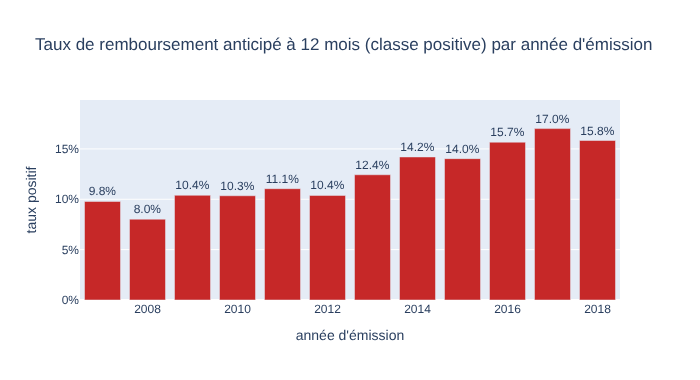

In [16]:
cible = report.tables["target_quality"]
fig = px.bar(
    cible,
    x="annee",
    y="taux_positif",
    text=cible["taux_positif"].map(lambda v: f"{v:.1%}"),
    title="Taux de remboursement anticipé à 12 mois (classe positive) par année d'émission",
    labels={"annee": "année d'émission", "taux_positif": "taux positif"},
    color_discrete_sequence=["#c62828"],
)
fig.update_traces(textposition="outside")
fig.update_layout(height=380, yaxis_tickformat=".0%")
fig.show()

In [17]:
statuts = raw["loan_status"].value_counts().rename("prets").to_frame()
statuts["ambigu"] = statuts.index.str.contains("Does not meet the credit policy")
statuts

,prets,ambigu
loan_status,,
Fully Paid,39964,False
Current,11534,False
Charged Off,8096,False
Does not meet the credit policy. Status:Fully Paid,1600,True
Does not meet the credit policy. Status:Charged Off,627,True
Late (31-120 days),292,False
In Grace Period,112,False
Late (16-30 days),52,False


**Lecture.** Taux positif de **14,8 % sur le complet** (12,7 % sur l'échantillon qui sur-pondère les
années anciennes), de 8,0 % en 2008 à 17,2 % en 2017 : un **déséquilibre modéré**, loin du seuil
d'alerte de 5 %. On **ne rééquilibre pas** (ni sous-échantillonnage, ni SMOTE, ni pondération de classe) :
en ALM ce qui compte est le **niveau** prédit (13 % annoncés doivent correspondre à 13 % observés), et
tout rééquilibrage détruit la calibration en gonflant artificiellement les probabilités. La **calibration
prime** donc sur le rappel ; l'AUC reste la métrique de classement et la **PR-AUC** est ajoutée en
métrique complémentaire parce qu'elle est plus sensible que l'AUC à la qualité sur la classe minoritaire.

Les **statuts ambigus** `Does not meet the credit policy. Status:…` (3,6 % de l'échantillon, moins de 0,1 % du complet,
tous antérieurs à 2011) décrivent des prêts accordés hors politique de crédit : la cible les traite selon
leur issue réelle (*Fully Paid* ou non), car le comportement de remboursement est observé, mais ils
appartiennent aux cohortes exclues de la référence. Sur le complet, l'audit ne trouve aucun prêt soldé
avec capital restant dû ni recouvrement incohérent : la ground truth est fiable.

## 4. Effet du nettoyage

`prepare_lending_club` applique `clean_impossible_values` par défaut. On compare les deux versions
sur l'échantillon : le nombre de lignes doit être identique (politique NaN, pas suppression) et seules
les colonnes à valeurs impossibles doivent gagner des NaN.

In [18]:
cleaned = lc.prepare_lending_club(raw, clean=True)
assert len(cleaned) == len(prepared), "le nettoyage ne doit supprimer aucune ligne"
delta = (cleaned.isna().sum() - prepared.isna().sum()).rename("valeurs_passees_a_NaN")
delta = delta[delta > 0].to_frame()
delta["part_des_lignes"] = delta["valeurs_passees_a_NaN"] / len(cleaned)
print(
    f"Lignes avant : {len(prepared):,} | après : {len(cleaned):,} | lignes touchées : {int((cleaned.isna() & ~prepared.isna()).any(axis=1).sum()):,}"
)
delta

Lignes avant : 57,559 | après : 57,559 | lignes touchées : 199


,valeurs_passees_a_NaN,part_des_lignes
annual_inc,17,0.0003
dti,23,0.0004
revol_util,159,0.0028


**Lecture.** Aucune ligne supprimée ; environ 0,35 % des lignes de l'échantillon voient une valeur
neutralisée, essentiellement `revol_util > 100 %`. Sur le complet, c'est **0,6 % des lignes**. Les
règles de contrôle (annuité, dernier paiement) ne sont pas « nettoyées » : elles portent sur des
colonnes post-octroi ou sur une cohérence qu'on ne saurait corriger sans inventer.

## 5. Aperçu du feature engineering

`engineer_features` ajoute sept colonnes, toutes connues à l'émission (vérifié par l'audit de fuite du
notebook 02). Elles traduisent directement trois constats de l'audit : manquant informatif
(`mort_acc_missing`), multicolinéarité (`installment_to_income` remplace la mensualité brute dans la
logistique) et lecture métier (`rate_spread`, `fico_band`).

In [19]:
engineered = lc.engineer_features(cleaned)
nouvelles = [*lc.ENGINEERED_NUMERIC_FEATURES, *lc.ENGINEERED_CATEGORICAL_FEATURES]
descriptions = {
    "loan_to_income": "montant du prêt / revenu annuel (taux d'effort en capital)",
    "installment_to_income": "mensualité x 12 / revenu annuel (taux d'effort en flux)",
    "rate_spread": "taux du prêt - taux moyen des prêts émis le même mois (cherté vs marché)",
    "credit_history_years": "années entre le premier compte de crédit et l'émission",
    "mort_acc_missing": "indicateur du manquant informatif détecté par l'audit",
    "term_x_rate": "durée x taux (coût total du crédit)",
    "fico_band": "classes FICO usuelles (<660, 660-699, 700-739, 740-779, 780+)",
}
apercu = pd.DataFrame(
    {
        "description": pd.Series(descriptions),
        "type": engineered[nouvelles].dtypes.astype(str),
        "manquants": engineered[nouvelles].isna().mean(),
    }
)
print(f"{cleaned.shape[1]} colonnes -> {engineered.shape[1]} colonnes")
apercu.style.set_properties(subset=["description"], **{"text-align": "left"})

25 colonnes -> 32 colonnes


,description,type,manquants
loan_to_income,montant du prêt / revenu annuel (taux d'effort en capital),float32,0.000365
installment_to_income,mensualité x 12 / revenu annuel (taux d'effort en flux),float32,0.000365
rate_spread,taux du prêt - taux moyen des prêts émis le même mois (cherté vs marché),float32,0.000000
credit_history_years,années entre le premier compte de crédit et l'émission,float32,0.000504
mort_acc_missing,indicateur du manquant informatif détecté par l'audit,float32,0.000000
term_x_rate,durée x taux (coût total du crédit),float32,0.000000
fico_band,"classes FICO usuelles (<660, 660-699, 700-739, 740-779, 780+)",string,0.000000


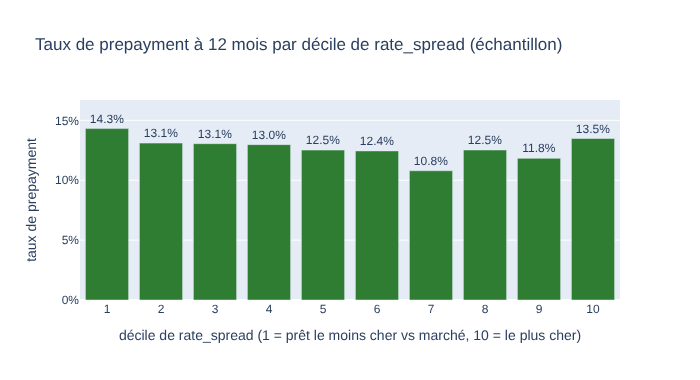

,decile_rate_spread,spread_median,taux_prepayment,prets
0,1,-6.2267,0.1431,5772
1,2,-4.5570,0.1310,5749
2,3,-2.9515,0.1305,5777
3,4,-1.6757,0.1297,5728
4,5,-0.7124,0.1252,5760
5,6,0.2211,0.1245,5761
6,7,1.2603,0.1079,5755
7,8,2.4177,0.1252,5757
8,9,4.2517,0.1182,5759
9,10,7.3760,0.1348,5741


In [20]:
engineered["decile_rate_spread"] = pd.qcut(engineered["rate_spread"], 10, labels=False) + 1
par_decile = (
    engineered.groupby("decile_rate_spread")
    .agg(
        spread_median=("rate_spread", "median"),
        taux_prepayment=(lc.TARGET, "mean"),
        prets=(lc.TARGET, "size"),
    )
    .reset_index()
)
fig = px.bar(
    par_decile,
    x="decile_rate_spread",
    y="taux_prepayment",
    text=par_decile["taux_prepayment"].map(lambda v: f"{v:.1%}"),
    hover_data={"spread_median": ":.2f", "prets": True},
    title="Taux de prepayment à 12 mois par décile de rate_spread (échantillon)",
    labels={
        "decile_rate_spread": "décile de rate_spread (1 = prêt le moins cher vs marché, 10 = le plus cher)",
        "taux_prepayment": "taux de prepayment",
    },
    color_discrete_sequence=["#2e7d32"],
)
fig.update_traces(textposition="outside")
fig.update_layout(height=380, yaxis_tickformat=".0%", xaxis={"dtick": 1})
fig.show()
par_decile

**Lecture honnête.** L'hypothèse métier est « plus le prêt est cher que le marché, plus il est
remboursé par anticipation ». Sur l'échantillon, la relation **n'est pas monotone** : le décile 10
(spread > +6 points) rembourse bien davantage, mais les déciles 1 à 9 oscillent autour de 12-14 %, et
le décile 1 (prêts les moins chers, emprunteurs de grade A) est lui aussi élevé. Le même calcul sur le
fichier complet donne 14,1-14,9 % pour les déciles 1 à 9 et **16,7 % pour le décile 10** : l'effet
existe, mais il est **concentré dans la queue haute** et confondu avec le grade (un spread élevé est
aussi un signe de risque, et les emprunteurs de grade A remboursent tôt parce qu'ils le peuvent). Le
`rate_spread` reste donc une feature utile, mais ce n'est pas un prédicteur linéaire : c'est une raison
de plus de préférer les arbres, et une interaction à surveiller en monitoring.

## 6. Verdict

**Les données sont exploitables** : sur le fichier complet aucun constat n'est critique, les cinq
avertissements sont compris et traités. Trois décisions en découlent, toutes codées dans le package et
non dans le notebook : **(1)** les 0,6 % de valeurs impossibles passent à **NaN** (ni suppression, ni
plafonnement) ; **(2)** le manquant informatif de `mort_acc` devient la feature **`mort_acc_missing`** ;
**(3)** **pas de rééquilibrage** de la cible à 14,8 %, la calibration primant en ALM, avec la PR-AUC en
métrique complémentaire. La référence de monitoring est fixée sur 2013-2015, là où les volumes
mensuels permettent une mesure.

**Ce que l'audit rejoue en production.** La recette Dataiku `dataiku/recipes/01_compute_alm_kpis.py`
calcule à chaque exécution les KPIs de qualité d'entrée du package (`missing_rate`, `out_of_range_rate`,
`unseen_categories_rate`, `schema_conformity`) et le scénario `02_scenario_monitoring.py` les soumet aux
checks du custom check `dataiku/checks/custom_check_monitoring_kpis.py`. Les contrôles de ce notebook se
retrouvent dans les fonctionnalités natives de DSS : **Explore / Analyze** pour les distributions, la
cardinalité et les aberrants (§ 3.4 à 3.6, lecture humaine à chaque nouvelle livraison) ; **Metrics &
Checks** sur le dataset d'entrée pour les doublons, les taux de manquants par colonne et le volume par
mois (§ 3.1, 3.3, 3.8, avec les mêmes seuils que `data_audit` : 0,1 % / 1 % de violations, 20 % de
manquants, 1 000 lignes par mois) ; **Data Quality rules** pour les règles métier d'impossibilité
(§ 3.2 : `revol_util` dans [0, 100], DTI dans [0, 100], revenu > 0, FICO dans [300, 850]) et pour la
cible (§ 3.9 : taux positif dans [5 %, 30 %] sur la période scorée). Un échec de ces règles bloque le
scénario avant le calcul des KPIs de dérive, comme l'audit de fuite bloque l'entraînement
(`train_lending_club.py` sort en code 2) et comme ce rapport conditionne la mise en référence.